<a href="https://colab.research.google.com/github/NagasaiSree/ML_LabActivity/blob/main/LinearRegression_TaxiTrips.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

url = "https://data.cityofchicago.org/resource/wrvz-psew.csv?$limit=5000"

df = pd.read_csv(url)

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (5000, 23)


,trip_id,taxi_id,trip_start_timestamp,trip_end_timestamp,trip_seconds,trip_miles,pickup_census_tract,dropoff_census_tract,pickup_community_area,dropoff_community_area,...,extras,trip_total,payment_type,company,pickup_centroid_latitude,pickup_centroid_longitude,pickup_centroid_location,dropoff_centroid_latitude,dropoff_centroid_longitude,dropoff_centroid_location
0,f3a139c0df3513324ff3f699bf40db2e84291e3a,9b48ad5744e86450fb4db78e7095a6827bafc43a6a9d9a...,2023-12-31T23:45:00.000,2024-01-01T00:00:00.000,1228.0,4.29,NaN,NaN,6.0,21.0,...,0.00,15.25,Cash,Sun Taxi,41.944227,-87.655998,POINT (-87.6559981815 41.9442266014),41.938666,-87.711211,POINT (-87.7112105933 41.9386661962)
1,011106b6114f83af0c17aace3867a464a7fc742b,4628ef9dfa973bdfe877c5aa9d9738f9dc1204e54f2f1a...,2023-12-31T23:45:00.000,2024-01-01T00:00:00.000,982.0,0.81,1.703108e+10,1.703108e+10,8.0,8.0,...,1.00,13.25,Credit Card,Chicago Independents,41.893216,-87.637844,POINT (-87.6378442095 41.8932163595),41.892508,-87.626215,POINT (-87.6262149064 41.8925077809)
2,ac9c9cd082dbdbfb67fc062dcb74ed713820e47f,75cf3a53aae5e5858361a7ca64f75d3407dc0a44d7bc42...,2023-12-31T23:45:00.000,2023-12-31T23:45:00.000,439.0,0.98,NaN,NaN,32.0,32.0,...,1.00,12.00,Credit Card,City Service,41.878866,-87.625192,POINT (-87.6251921424 41.8788655841),41.878866,-87.625192,POINT (-87.6251921424 41.8788655841)
3,1d518052b3bcea69bdfec3508886d7551406202d,ea8e6df913a36562d8eddf662abe7722f4c0dc08527e98...,2023-12-31T23:45:00.000,2024-01-01T00:00:00.000,1080.0,8.90,NaN,NaN,8.0,40.0,...,0.00,24.50,Cash,Taxi Affiliation Services,41.899602,-87.633308,POINT (-87.6333080367 41.899602111),41.792357,-87.617931,POINT (-87.6179313803 41.7923572233)
4,f40c2cda1cea33c2265a34b2ce1eb454067ad8d2,3618045f9110d4d88482266ade23659c1a50d32ac37f20...,2023-12-31T23:45:00.000,2023-12-31T23:45:00.000,0.0,0.00,NaN,NaN,24.0,24.0,...,11.25,14.50,Credit Card,Taxi Affiliation Services,41.901207,-87.676356,POINT (-87.6763559892 41.9012069941),41.901207,-87.676356,POINT (-87.6763559892 41.9012069941)


In [ ]:
print(df.columns.tolist())

['trip_id', 'taxi_id', 'trip_start_timestamp', 'trip_end_timestamp', 'trip_seconds', 'trip_miles', 'pickup_census_tract', 'dropoff_census_tract', 'pickup_community_area', 'dropoff_community_area', 'fare', 'tips', 'tolls', 'extras', 'trip_total', 'payment_type', 'company', 'pickup_centroid_latitude', 'pickup_centroid_longitude', 'pickup_centroid_location', 'dropoff_centroid_latitude', 'dropoff_centroid_longitude', 'dropoff_centroid_location']


In [ ]:
print(df[['trip_miles', 'fare']].head())

   trip_miles   fare
0        4.29  15.25
1        0.81   8.75
2        0.98   6.50
3        8.90  24.50
4        0.00   3.25


In [ ]:
df = df[['trip_miles', 'fare']]

df['trip_miles'] = pd.to_numeric(df['trip_miles'], errors='coerce')
df['fare'] = pd.to_numeric(df['fare'], errors='coerce')

df = df.dropna()

print(df.shape)
df.head()

(4990, 2)


,trip_miles,fare
0,4.29,15.25
1,0.81,8.75
2,0.98,6.50
3,8.90,24.50
4,0.00,3.25


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X = df[['trip_miles']]
y = df['fare']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Coefficient:", model.coef_[0])
print("Intercept:", model.intercept_)
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred) ** 0.5)
print("R² Score:", r2_score(y_test, y_pred))

Coefficient: 1.9803954573564622
Intercept: 9.22318703625802
MAE: 5.295985187087399
RMSE: 10.06685820105075
R² Score: 0.6497139810674406


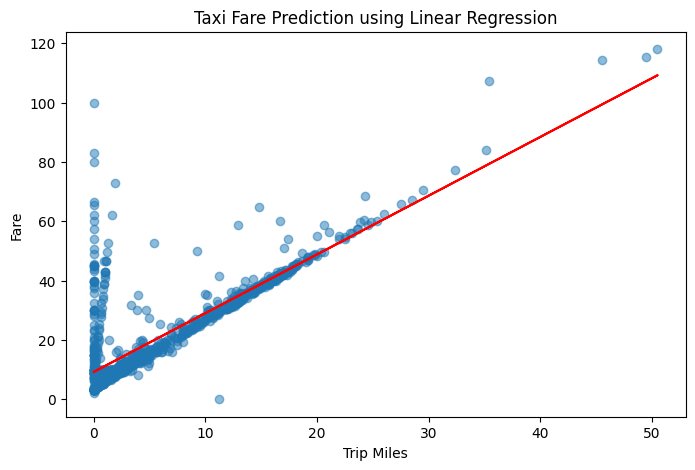

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.scatter(X_test, y_test, alpha=0.5)
plt.plot(X_test, y_pred, color='red')

plt.xlabel("Trip Miles")
plt.ylabel("Fare")
plt.title("Taxi Fare Prediction using Linear Regression")
plt.show()